In [1]:
import pandas as pd
import numpy as np

In [8]:
true = pd.read_excel('New folder/dji_0004_hs0600d_L774.xlsx')
predict = pd.read_excel('New folder\hasildeteksi.xlsx')

In [10]:
predict["Vehicle Types"] = predict["Vehicle Types"].astype(str).str.replace(r'[\d\s.]+', '', regex=True)

In [15]:
# predict['frame_count'] = predict['frame_count'].astype(int)
# predict['minute'] = predict['frame_count'] // 60
predict

,Unnamed: 0,Vehicle Types,Coordinates,Time
0,0,car,"(739, 593)",0.016683
1,1,motorcycle,"(728, 571)",0.016683
2,2,car,"(742, 558)",0.500500
3,3,motorcycle,"(743, 577)",0.500500
4,4,motorcycle,"(743, 579)",1.217883
...,...,...,...,...
525,525,motorcycle,"(743, 596)",298.765133
526,526,motorcycle,"(743, 558)",299.115483
527,527,car,"(743, 579)",299.349050
528,528,motorcycle,"(742, 595)",299.615983


In [17]:
true.drop(true.tail(1).index, inplace=True) # ada keterangan tambahan untuk koordinat counting line yang tidak dibutuhkan dalam analisis
true

,ganti lajur,motor,1
0,tidak ganti lajur,mobil,0.066733
1,tidak ganti lajur,mobil,0.266933
2,tidak ganti lajur,motor,0.417083
3,tidak ganti lajur,motor,1.167833
4,tidak ganti lajur,mobil,1.534867
...,...,...,...
498,tidak ganti lajur,motor,298.715083
499,tidak ganti lajur,motor,299.032067
500,tidak ganti lajur,mobil,299.182217
501,tidak ganti lajur,motor,299.549250


In [19]:
df_compare = predict.copy()


In [20]:
df_compare

,Unnamed: 0,Vehicle Types,Coordinates,Time
0,0,car,"(739, 593)",0.016683
1,1,motorcycle,"(728, 571)",0.016683
2,2,car,"(742, 558)",0.500500
3,3,motorcycle,"(743, 577)",0.500500
4,4,motorcycle,"(743, 579)",1.217883
...,...,...,...,...
525,525,motorcycle,"(743, 596)",298.765133
526,526,motorcycle,"(743, 558)",299.115483
527,527,car,"(743, 579)",299.349050
528,528,motorcycle,"(742, 595)",299.615983


In [ ]:
df_compare.drop(columns=['Unnamed: 0'], inplace=True)

In [18]:
true = true.rename(columns={'1': 'time'})
# true['minute'] = true['1'] // 60
true

,ganti lajur,motor,time
0,tidak ganti lajur,mobil,0.066733
1,tidak ganti lajur,mobil,0.266933
2,tidak ganti lajur,motor,0.417083
3,tidak ganti lajur,motor,1.167833
4,tidak ganti lajur,mobil,1.534867
...,...,...,...
498,tidak ganti lajur,motor,298.715083
499,tidak ganti lajur,motor,299.032067
500,tidak ganti lajur,mobil,299.182217
501,tidak ganti lajur,motor,299.549250


In [7]:
grouped_car_predict = []
grouped_motor_predict = []
for group in predict['minute'].unique():
    grouped_car_predict.append(predict[(predict['minute'] == group) & (predict['counted_vec_types'] == 'car')]['minute'].count())
    grouped_motor_predict.append(predict[(predict['minute'] == group) & (predict['counted_vec_types'] == 'motorcycle')]['minute'].count())

grouped_car_true = []
grouped_motor_true = []
for group in true['minute'].unique():
    grouped_car_true.append(true[(true['minute'] == group) & (true['motor'] == 'mobil')]['minute'].count())
    grouped_motor_true.append(true[(true['minute'] == group) & (true['motor'] == 'motor')]['minute'].count())


In [8]:
grouped_car_predict.pop()
grouped_motor_predict.pop()
grouped_car_true.pop()
grouped_motor_true.pop()

np.int64(1)

In [9]:
predict['counted_vec_types'].count()

np.int64(846)

In [10]:
true['motor'].value_counts()

motor
motor    406
mobil     97
Name: count, dtype: int64

In [11]:
count = 5
abnormal_indexes = []
abnormal_differences = []
differences = []
prev_frame_count = 0
for index, row in predict.iterrows():
    difference = row['frame_count'] - prev_frame_count
    differences.append(difference)
    # print(f"Row {index}: {difference}")
    prev_frame_count = row['frame_count']
    if difference < 0.1:
        abnormal_indexes.append(index)
        abnormal_differences.append(difference)
abnormal_rows = {
    "index": abnormal_indexes,
    "difference": abnormal_differences
}

In [12]:
grouped_car_true

[np.int64(12), np.int64(24), np.int64(18), np.int64(19), np.int64(24)]

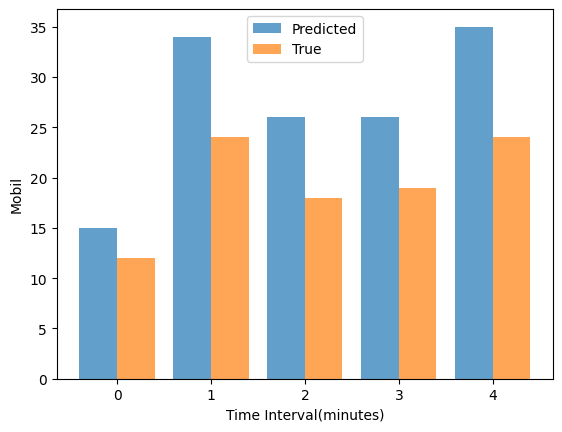

In [13]:
import numpy as np
from scipy.interpolate import make_interp_spline
import matplotlib.pyplot as plt


y = np.array(grouped_car_predict)  # Mengambil 4 nilai terakhir dari differences
y2 = np.array(grouped_car_true)  # Mengambil 4 nilai terakhir dari differences
x = np.arange(len(grouped_car_predict))  # Membuat array x sesuai dengan panjang y
x_labels = (x)

fig, ax = plt.subplots()
ax.bar(x - 0.2, y, width=0.4, alpha=0.7, label='Predicted')
ax.bar(x + 0.2, y2, width=0.4, alpha=0.7, label='True')
ax.legend()
# Batang
# ax.bar(x, y, alpha=0.7)
# ax.bar(x, y2, alpha=0.7)

# Atur label sumbu x sebagai waktu dalam detik
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_xlabel('Time Interval(minutes)')
ax.set_ylabel('Mobil')

# Garis melengkung
x_smooth = np.linspace(x.min(), x.max(), 300)
# y_smooth = make_interp_spline(x, y, k=3)(x_smooth)

# ax.plot(x_smooth, y_smooth, linewidth=2)

plt.show()

In [14]:
highest_density_car = 1

predict_car_minute_highest = predict[(predict['minute'] == highest_density_car) & (predict['counted_vec_types'] == 'car')]
predict_car_minute_highest['frame/10'] = predict_car_minute_highest['frame_count'] // 10
true_car_minute_highest = true[(true['minute'] == highest_density_car) & (true['motor'] == 'mobil')]
true_car_minute_highest['frame/10'] = true_car_minute_highest['1'] // 10

C:\Users\ACER\AppData\Local\Temp\ipykernel_6616\767336320.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predict_car_minute_highest['frame/10'] = predict_car_minute_highest['frame_count'] // 10
C:\Users\ACER\AppData\Local\Temp\ipykernel_6616\767336320.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  true_car_minute_highest['frame/10'] = true_car_minute_highest['1'] // 10


In [34]:
predict_car_minute_highest_grouped = predict_car_minute_highest.groupby('frame/10').size().reset_index(name='count')
# predict_car_minute_highest_grouped['frame/10'] = predict_car_minute_highest_grouped['frame/10'] * 10
true_car_minute_highest_grouped = true_car_minute_highest.groupby('frame/10').size().reset_index(name='count')
# true_car_minute_highest_grouped['frame/10'] = true_car_minute_highest_grouped['frame/10'] * 10

In [35]:
predict_car_minute_highest_grouped

,frame/10,count
0,6,4
1,7,3
2,8,2
3,9,11
4,10,7
5,11,7


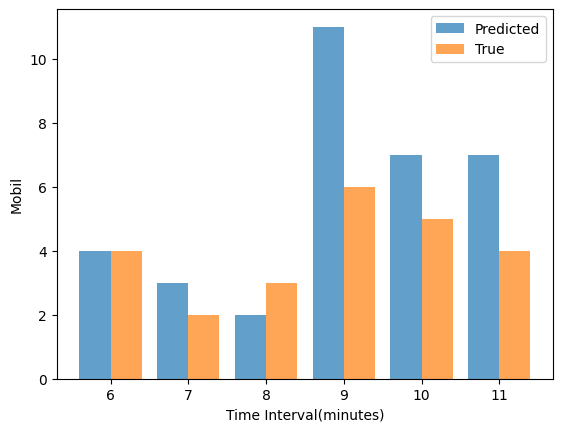

In [ ]:
y = np.array(predict_car_minute_highest_grouped['count'])  # Mengambil 4 nilai terakhir dari differences
y2 = np.array(true_car_minute_highest_grouped['count'])  # Mengambil 4 nilai terakhir dari differences
x = np.array(true_car_minute_highest_grouped['frame/10'])  # Membuat array x sesuai dengan panjang y
x_labels = (x)

fig, ax = plt.subplots()
ax.bar(x - 0.2, y, width=0.4, alpha=0.7, label='Predicted')
ax.bar(x + 0.2, y2, width=0.4, alpha=0.7, label='True')
ax.legend()

# Atur label sumbu x sebagai waktu dalam detik
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_xlabel('Time Interval(per 10 frames)')
ax.set_ylabel('Mobil')

# ax.plot(x_smooth, y_smooth, linewidth=2)

plt.show()

In [16]:
highest_density_motorcycle = 3

predict_motorcycle_minute_highest = predict[(predict['minute'] == highest_density_motorcycle) & (predict['counted_vec_types'] == 'motorcycle')]
predict_motorcycle_minute_highest['frame/10'] = predict_motorcycle_minute_highest['frame_count'] // 10
true_motorcycle_minute_highest = true[(true['minute'] == highest_density_motorcycle) & (true['motor'] == 'motor')]
true_motorcycle_minute_highest['frame/10'] = true_motorcycle_minute_highest['1'] // 10

C:\Users\ACER\AppData\Local\Temp\ipykernel_6616\67281317.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predict_motorcycle_minute_highest['frame/10'] = predict_motorcycle_minute_highest['frame_count'] // 10
C:\Users\ACER\AppData\Local\Temp\ipykernel_6616\67281317.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  true_motorcycle_minute_highest['frame/10'] = true_motorcycle_minute_highest['1'] // 10


In [38]:
predict_motor_minute_highest_grouped = predict_motorcycle_minute_highest.groupby('frame/10').size().reset_index(name='count')
# predict_motor_minute_highest_grouped['frame/10'] = predict_motor_minute_highest_grouped['frame/10'] * 10
true_motor_minute_highest_grouped = true_motorcycle_minute_highest.groupby('frame/10').size().reset_index(name='count')
# true_motor_minute_highest_grouped['frame/10'] = true_motor_minute_highest_grouped['frame/10'] * 10

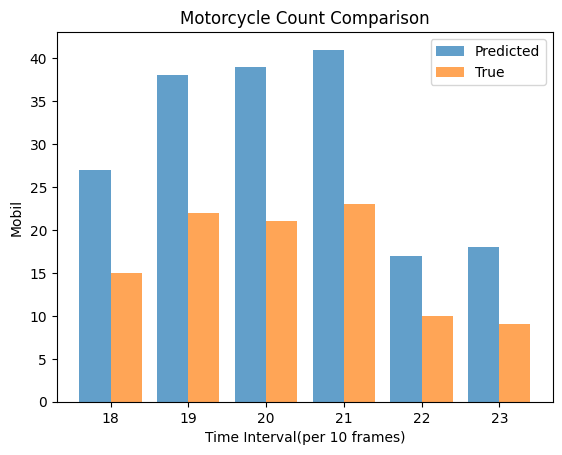

In [40]:
y = np.array(predict_motor_minute_highest_grouped['count'])  # Mengambil 4 nilai terakhir dari differences
y2 = np.array(true_motor_minute_highest_grouped['count'])  # Mengambil 4 nilai terakhir dari differences
x = np.array(true_motor_minute_highest_grouped['frame/10'])  # Membuat array x sesuai dengan panjang y
x_labels = (x)

fig, ax = plt.subplots()
ax.bar(x - 0.2, y, width=0.4, alpha=0.7, label='Predicted')
ax.bar(x + 0.2, y2, width=0.4, alpha=0.7, label='True')
ax.legend()

# Atur label sumbu x sebagai waktu dalam detik
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_xlabel('Time Interval(per 10 frames)')
ax.set_ylabel('Mobil')
ax.set_title('Motorcycle Count Comparison')

# ax.plot(x_smooth, y_smooth, linewidth=2)

plt.show()

In [18]:
grouped_car_highest_predict = []
grouped_motor_highest_predict = []
for group in predict['minute'].unique():
    grouped_car_highest_predict.append(predict[(predict['minute'] == group) & (predict['counted_vec_types'] == 'car')]['minute'].count())
    grouped_motor_highest_predict.append(predict[(predict['minute'] == group) & (predict['counted_vec_types'] == 'motorcycle')]['minute'].count())

grouped_car_true = []
grouped_motor_true = []
for group in true['minute'].unique():
    grouped_car_true.append(true[(true['minute'] == group) & (true['motor'] == 'mobil')]['minute'].count())
    grouped_motor_true.append(true[(true['minute'] == group) & (true['motor'] == 'motor')]['minute'].count())


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (5,) and arg 1 with shape (6,).

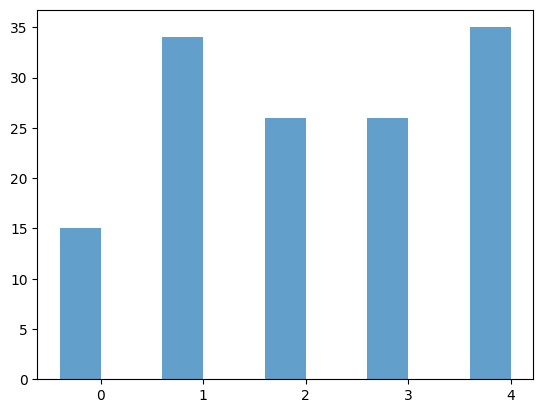

In [19]:
y = np.array(grouped_car_predict)  # Mengambil 4 nilai terakhir dari differences
y2 = np.array(grouped_car_true)  # Mengambil 4 nilai terakhir dari differences
x = np.arange(len(grouped_car_predict))  # Membuat array x sesuai dengan panjang y
x_labels = (x)

fig, ax = plt.subplots()
ax.bar(x - 0.2, y, width=0.4, alpha=0.7, label='Predicted')
ax.bar(x + 0.2, y2, width=0.4, alpha=0.7, label='True')
ax.legend()
# Batang
# ax.bar(x, y, alpha=0.7)
# ax.bar(x, y2, alpha=0.7)

# Atur label sumbu x sebagai waktu dalam detik
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_xlabel('Time Interval(minutes)')
ax.set_ylabel('Mobil')

# Garis melengkung
x_smooth = np.linspace(x.min(), x.max(), 300)
# y_smooth = make_interp_spline(x, y, k=3)(x_smooth)

# ax.plot(x_smooth, y_smooth, linewidth=2)

plt.show()

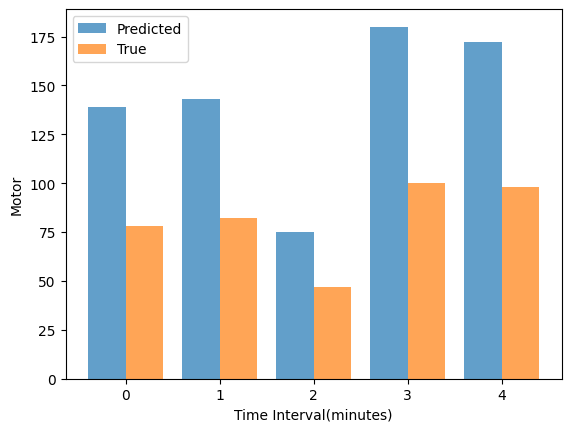

In [ ]:
y = np.array(grouped_motor_predict)  # Mengambil 4 nilai terakhir dari differences
y2 = np.array(grouped_motor_true)  # Mengambil 4 nilai terakhir dari differences
x = np.arange(len(grouped_motor_predict))  # Membuat array x sesuai dengan panjang y
x_labels = (x)

fig, ax = plt.subplots()
ax.bar(x - 0.2, y, width=0.4, alpha=0.7, label='Predicted')
ax.bar(x + 0.2, y2, width=0.4, alpha=0.7, label='True')
ax.legend()
# Batang
# ax.bar(x, y, alpha=0.7)
# ax.bar(x, y2, alpha=0.7)

# Atur label sumbu x sebagai waktu dalam detik
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_xlabel('Time Interval(minutes)')
ax.set_ylabel('Motor')

# Garis melengkung
x_smooth = np.linspace(x.min(), x.max(), 300)
# y_smooth = make_interp_spline(x, y, k=3)(x_smooth)

# ax.plot(x_smooth, y_smooth, linewidth=2)